In [6]:
import matplotlib.pyplot as plt  
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42

Saved: /home/feity/compare_release/deepict/sweep/hsp60_sweep_metrics_best_per_threshold.pdf


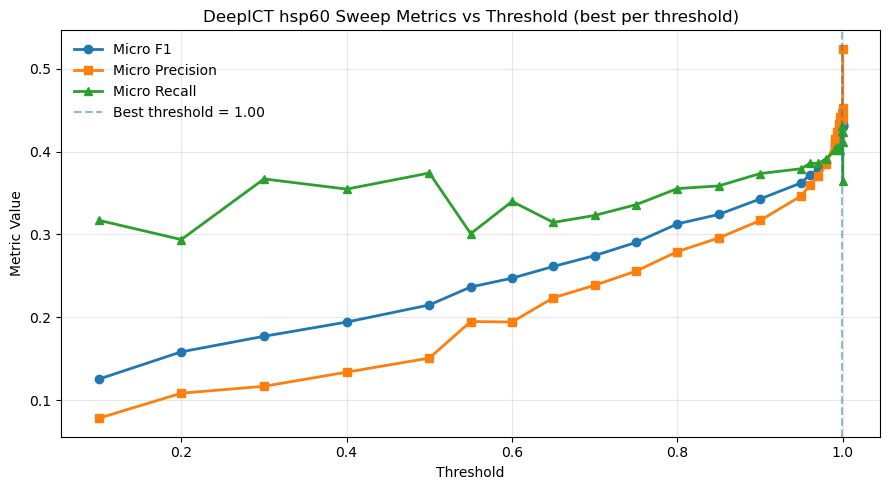

Saved: /home/feity/compare_release/deepict/sweep/ribosome_sweep_metrics_best_per_threshold.pdf


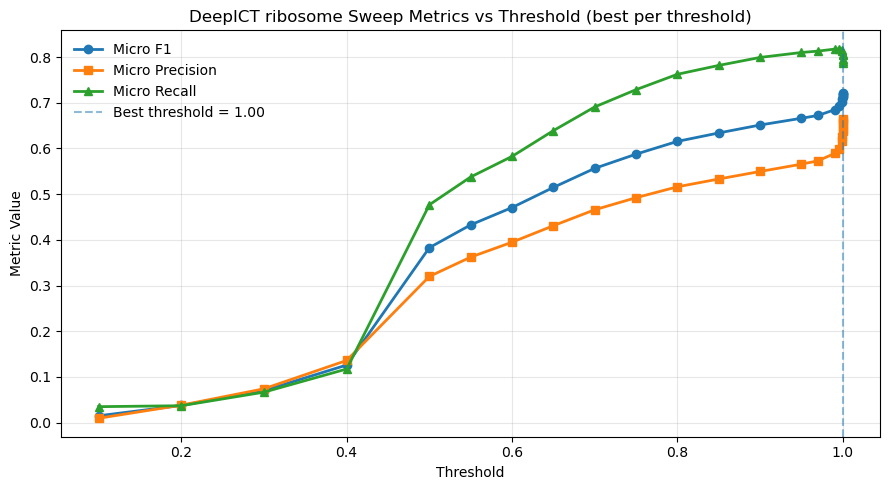

In [12]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Input sweep tables and output folder.
SWEEP_DIR = Path('/home/feity/compare_release/deepict/sweep')
FILES = {
    'hsp60': SWEEP_DIR / 'hsp60_pp_grid.csv',
    'ribosome': SWEEP_DIR / 'ribo_pp_grid.csv',
}

for name, csv_path in FILES.items():
    if not csv_path.exists():
        raise FileNotFoundError(f'Missing file: {csv_path}')

    df = pd.read_csv(csv_path)

    required_cols = {'threshold', 'precision', 'recall', 'f1'}
    missing = required_cols.difference(df.columns)
    if missing:
        raise ValueError(f'{csv_path} missing columns: {sorted(missing)}')

    # Keep the best post-process setting at each threshold.
    best_by_thr = (
        df.sort_values(['threshold', 'f1'], ascending=[True, False])
          .drop_duplicates(subset=['threshold'], keep='first')
          .sort_values('threshold')
          .reset_index(drop=True)
    )

    best_row = best_by_thr.loc[best_by_thr['f1'].idxmax()]
    best_thr = float(best_row['threshold'])

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(best_by_thr['threshold'], best_by_thr['f1'], marker='o', linewidth=2, label='Micro F1')
    ax.plot(best_by_thr['threshold'], best_by_thr['precision'], marker='s', linewidth=2, label='Micro Precision')
    ax.plot(best_by_thr['threshold'], best_by_thr['recall'], marker='^', linewidth=2, label='Micro Recall')

    ax.axvline(best_thr, linestyle='--', alpha=0.5, label=f'Best threshold = {best_thr:.2f}')

    ax.set_title(f'DeepICT {name} Sweep Metrics vs Threshold (best per threshold)')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Metric Value')
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False)
    fig.tight_layout()

    out_png = SWEEP_DIR / f'{name}_sweep_metrics_best_per_threshold.pdf'
    fig.savefig(out_png, dpi=220, bbox_inches='tight')
    print('Saved:', out_png)

    plt.show()

hsp60 mean F1 by threshold:
 threshold       f1
  0.300000 0.175772
  0.400000 0.196322
  0.500000 0.224283
  0.600000 0.252618
  0.700000 0.270297
  0.800000 0.302337
  0.900000 0.326722
  0.950000 0.339681
  0.990000 0.376080
  0.995000 0.381939
  0.999000 0.388559
  0.999500 0.387120
  0.999900 0.378501
  0.999950 0.376640
  0.999990 0.363774
  0.999995 0.365307



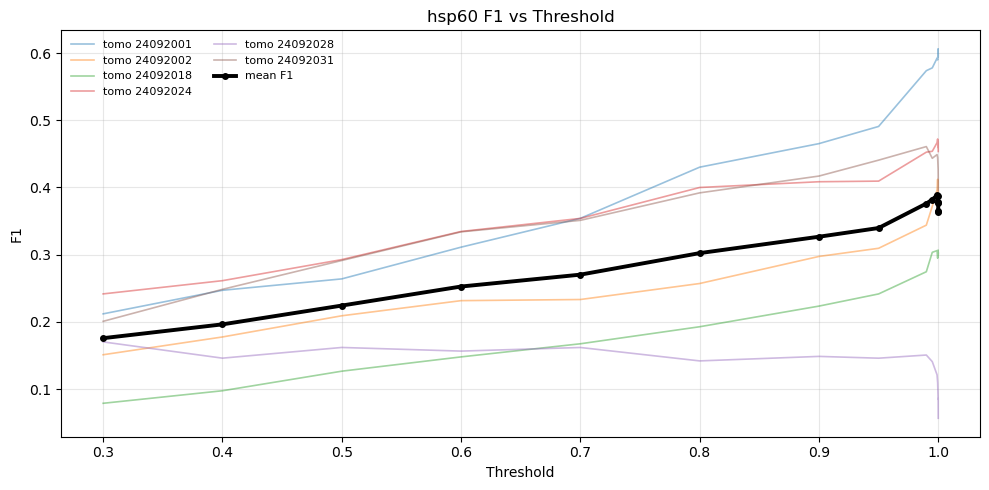

ribosome mean F1 by threshold:
 threshold       f1
  0.300000 0.164087
  0.400000 0.262824
  0.500000 0.373824
  0.600000 0.454593
  0.700000 0.532599
  0.800000 0.586935
  0.900000 0.625555
  0.950000 0.639415
  0.990000 0.655548
  0.995000 0.665133
  0.999000 0.676505
  0.999500 0.683697
  0.999900 0.691733
  0.999950 0.693104
  0.999990 0.698525
  0.999995 0.700471
  0.999999 0.703243



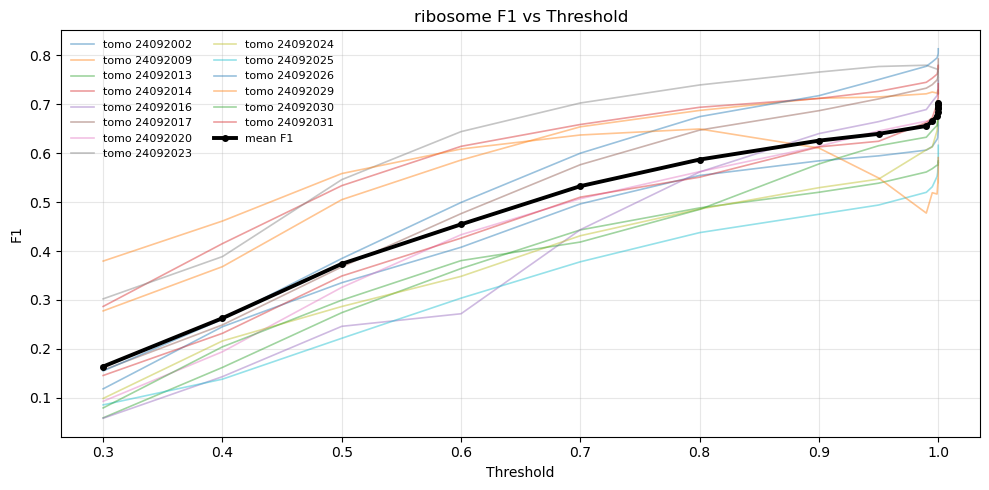

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

paths = {
    "hsp60": "/home/feity/compare_release/deepict/hsp60_pp_per_tomo_f1.csv",
    "ribosome": "/home/feity/compare_release/deepict/ribo_pp_per_tomo_f1.csv",
}

for name, path in paths.items():
    df = pd.read_csv(path)

    if {"threshold", "tomo", "f1"} - set(df.columns):
        raise ValueError(f"{path} must contain threshold, tomo, and f1 columns")

    per_curve = (
        df.groupby(["threshold", "tomo"], as_index=False)["f1"]
          .max()
          .sort_values(["tomo", "threshold"])
          .reset_index(drop=True)
    )

    mean_curve = (
        per_curve.groupby("threshold", as_index=False)["f1"]
                 .mean()
                 .sort_values("threshold")
                 .reset_index(drop=True)
    )

    print(f"{name} mean F1 by threshold:")
    print(mean_curve.to_string(index=False))
    print()

    fig, ax = plt.subplots(figsize=(10, 5))
    for tomo, tomo_df in per_curve.groupby("tomo"):
        ax.plot(
            tomo_df["threshold"],
            tomo_df["f1"],
            linewidth=1.2,
            alpha=0.45,
            label=f"tomo {tomo}",
        )

    ax.plot(
        mean_curve["threshold"],
        mean_curve["f1"],
        color="black",
        linewidth=2.8,
        marker="o",
        markersize=4,
        label="mean F1",
    )

    ax.set_title(f"{name} F1 vs Threshold")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("F1")
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False, ncol=2, fontsize=8)
    fig.tight_layout()
    plt.savefig(f"/home/feity/compare_release/deepict/sweep/{name}_pp_grid.pdf")
    plt.show()
